# 📘 10.2 Neural ODEs
###

This notebook introduces Neural ODEs, which unlike Neural Networks, focus on learning the ODE associated with the dynamics of the system, rather than trying to directly predict the output of the system. The process of defining and training the network is similar to what you have seen before, but this approach has numerous outputs when applied to a dynamical system. This notebook will merge concept from weeks 5 and 7 to demonstrate a new approach to Machine Learning.

---

### 🎯 Learning Objectives
> By the end of this notebook, you should be able to:
>
> *   **Define** what a Neural Ordinary Differential Equation (Neural ODE) is and its purpose in modeling dynamical systems;
> *   **Understand** how a neural network is integrated into an ODE solver to learn the underlying vector field;
> *   **Generate** training data suitable for a Neural ODE from known ODEs;
> *   **Explain** the training process of a Neural ODE, including the role of the loss function and optimization;
> *   **Compare** the characteristics and performance of Neural ODEs against traditional neural networks for time-series prediction;
> *   **Discuss** the key advantages of Neural ODEs, such as their extrapolation capabilities, physical consistency, and generation of smooth trajectories.

## 📂 10.2.0 How to use this notebook

This notebook begins by providing a refresher and formalisation of the concepts behind the training of a standard Neural Network, before explaining how this framework can enable the learning of an ODE rather than a direct output.

> ### 🧭 Theory preface
> You should understand how neuron layers provide a forward output and the basics of backprojection in order to gain an estimate of how the parameters of a neuron influence the loss function.
>
> The concept and benefit of the neural ODEs are conveyed through a practical demonstration rather than any mathematical derivation.
>
> The final section, 10.2.7, is intended to provide some insight into how the neural ODE optimisation and backproject can account for the integeration of the ODE output. Section 10.2.7 is extension content that *will not be examined*.

The basis for this notebook comes from the recent paper by Worsham and Kalita (2025), Digital Engineering, vol 6. https://doi.org/10.1016/j.dte.2025.100060. The paper provides a more detailed look at Neural ODEs with links to multiple examples in Engineering and Science. This is still a relatively immature area, the full extent of these approaches are still being actively explored.

## 📂 10.2.1 Neural Networks to ODEs

---

As discussed in [Notebook 5.4](https://colab.research.google.com/drive/1ab2YEV003pMehwpF0MJBWAY8ZTasADxW?usp=sharing), standard Neural Networks focus around discrete inputs (e.g. labels assigned to features) and *learning* to connect these to a target output. In general, these inputs are focused on a single instant, e.g. an image taken at one instant in time. Temporal information can be included in these models by adding additional inputs with different time stamps, or tagging inputs by a temporal offset. If a high sampling rates is needed over a along time scale, then a larger input sequence is required. Even if you do accommodate a sufficient temporal sequence, these are still *static instances* and only provide a *static awareness* of the system. Such models will subsequently provide predictions that depend on the same temporal spacing and input rates.

In practice, many of the system with which engineers are concerned are *dynamic systems*, with a state that *continuously* varies with time. This raises the question: can we apply machine learning to problems in the continuous-time domain?

One of the core deep learning models employed in the continuous-time domain is the neural ordinary differential equation (abbreviated as **neural ODE**, or **NODE**). As the name suggest, this is essentially a machine learning implementation of an ordinary differential equation. Where so far we have had a known ODE and attempted to solve for a solution that satisfies this ODE, with a neural ODE we instead have the physical response of a system and attempt to learn the underlying ODE.

<figure>
  <img src="https://drive.google.com/uc?id=1EN2bRfoG9LNeea7OgmmMg8SrcX5UaV_v" alt="" style="width:100%;max-width:400px;">
  <figcaption style="text-align: center; font-style: italic; margin-top: 5px;">
    Figure 10.1. (a) True (physics-based) and (b) learned (neural ODE) plots of a pendulums phase or angle vs its angular velocity - From Worsham and Kalita (2025), Digital Engineering, vol 6. https://doi.org/10.1016/j.dte.2025.100060.
  </figcaption>
</figure>

Say we have a problem given a vector at starting time $t_0$, $\mathbf{x}⁡(t_0)$, and we with to determine the value of the vector at some final time $t_f$, $\mathbf{x⁡}(t_f)$. By now you should recognise this as an  initial value problem (IVP). To solve this problem, you need to know how $\mathbf{x}(t)$ changes over time, i.e. you need the ODE. However, as we have seen, the solution will depend on your step size. Too large and the solution may be unstable or miss rapid transients, too small and the solution will take a long time to solve. In the limit as the step size tends to zero, we get the a *continuous* framework,

$$ x(t_f) = x(t_0) + \int^{t_f}_{t_0} f(t,x(t)) \mbox{d}t,\tag{10.6}$$

where $f$ is the ODE that governs the change in $x$ with respect to time. It is this *continuous* function that we ultimately want to know, such that unlike a discrete time series, it is independent of the time step.

Traditionally, the continuous ODEs we use in engineering are analytically derived by conservation principles and Newton's laws of motion. *What do we do if we don't know the physics that are governing our problem*?



## 📂 10.2.2 Revisit Neural Network Training

---

To understand a Neural ODE, it is import to first revisit what it is that constitutes a standard Neural Network.

Consider a Neutral Net - a Multi-Layer Perceptron (MLP) - with the architecture depicted in figure 10.2, i.e. Three layers, with a *forward* calculation that goes from an input array $\mathbf{x}_0$ to an output $\mathbf{x}_3$, with $\mathbf{x}_1$ and $\mathbf{x}_2$ being the output of the first and second layers, respectively.

<figure>
  <img src="https://drive.google.com/uc?id=1Qe2K-tVrGcd1LsQiUp91TkoUspbcYsDP" alt="" style="width:100%;max-width:400px;">
  <figcaption style="text-align: center; font-style: italic; margin-top: 5px;">
    Figure 10.1. A 3-layer Perceptron with forward and backward pass computations - From Worsham and Kalita (2025), Digital Engineering, vol 6. https://doi.org/10.1016/j.dte.2025.100060.
  </figcaption>
</figure>

> ### 📖 Definition
> **Perceptron** refers to a classic artificial neuron that uses a hard threshold step function for binary classification, with output 0 or 1.

The terms $f_{\theta_1$}\dots f_{\theta_3$}$ represent the non-linear activation funcations associated with layers 1, 2 and 3, respectively. The terms associated with each layer are defined here as $\theta_1, \theta_2, \theta_3$, for a corresponding output,

$$ \mathbf{x}_3 = f_{\theta_3}\left(f_{\theta_2}\left(f_{\theta_1}(\mathbf{x}_0)\right)\right).$$

The role of the learning processes is to find the optimal set of parameters, $\theta_i$, that ensure that $\mathbf{x}_3$ achieves the desired output. During this process, the difference between the model output, $\mathbf{x}_3$ and the training data output $\mathbf{y}$ is represented by the *loss* function,

$$\mathcal{L}(\mathbf{x}_3, \mathbf{y}).$$

We can express the learning objectives as
$$\theta_i = arg \min_\theta \sum^N_{j=0}\mathcal{L}\left(\mathbf{x}^{(j)}_3, \mathbf{y}^{(j)}\right),$$
i.e. finding the parameters $\theta_i$ that minimise the loss function, over a series of N training inputs.  

Learning is typically performed via a *Gradient Descent* method, in which you change the loss due to each parameters is represented via the gradient $\partial \mathcal{L}/\partial \theta_i$. These gradients are typically deduced from the training data via *back propagation*.

In this case, we have three layers and three sets of correponding parameter that all affect the output and the loss. From the *chain rule* we can express these as

\begin{align} \frac{\partial \mathcal{L}}{\partial \theta_3} &= \frac{\partial \mathcal{L}}{\partial \mathbf{x}_3} \frac{\partial \mathbf{x}_3}{\partial \theta_3},\\
\frac{\partial \mathcal{L}}{\partial \theta_2} &= \frac{\partial \mathcal{L}}{\partial \mathbf{x}_3} \frac{\partial \mathbf{x}_3}{\partial \mathbf{x}_2} \frac{\partial \mathbf{x}_2}{\partial \theta_2},\\
\frac{\partial \mathcal{L}}{\partial \theta_3} &= \frac{\partial \mathcal{L}}{\partial \mathbf{x}_3} \frac{\partial \mathbf{x}_3}{\partial \mathbf{x}_2} \frac{\partial \mathbf{x}_2}{\partial \mathbf{x}_1} \frac{\partial \mathbf{x}_1}{\partial \theta_1},\\
\end{align}

where the values of $\mathbf{x}_i$ in the numerator can be replaced with their evaluations functions, e.g. $\mathbf{x}_3 = f_{\theta_3}(\mathbf{x}_2)$ to match the forms given in the backward step of Figure 10.1. The particular forms of the loss gradients is chosen such that the gradients for the final layer can be *backpropagated* to get the gradients of the previous layer and so on. This has the advantage that we can determine the loss gradients from only the output and the loss.

Starting at the output, the partial derivative $\partial \mathcal{L}/\partial \mathbf{x}_3$ comes chosen form of the loss function. E.g. if the loss is the square of the difference between the output and the corresponding training data (the factor of a half is added for convience and doesn't impact the conditions at which the loss is a minimum),
$$ \mathcal{L}(\mathbf{x}_3, \mathbf{y}) = \frac{1}{2}\left(\mathbf{x}_3 - \mathbf{y}\right)^2,$$
then
$$ \frac{\partial \mathcal{L}}{\partial \mathbf{x}_3} = \mathbf{x}_3 - \mathbf{y}.$$

I.e. this terms is analytically defined by our loss function.

The gradient $\partial \mathbf{x}_3 \partial \theta_3$ depends on the chosen form of the activation function $f_{\theta_3}(\mathbf{x}_2)$. Since,

$$ \mathbf{x}_3 = f_{\theta_3}\left(f_{\theta_2}\left(f_{\theta_1}(\mathbf{x}_0)\right)\right),$$

$$\frac{\partial \mathbf{x}_3}{\partial \theta_3} = \frac{\partial f_{\theta_3}\left(f_{\theta_2}\left(f_{\theta_1}(\mathbf{x}_0)\right)\right)}{\partial \theta_3},$$

given that only $f_{\theta_3}$ depends on $\theta_3$. The gradients of each layer can generally be defined analytically, but they depends on the type of neurons.

If the third layer consisted of a single modern perceptron which takes an input $x_2$ with a weight $W$, a bias $b$ and an activation $\sigma$, such that a forward pass arrives at an output $x_{3}$ as given by

$$ u = Wx_2 + b, \qquad x_{3} = \sigma(u),$$

where $\sigma(u)$ is a differentiable function like $\tanh(u)$. This would results in a *forward function*

$$ x_{3} = \tanh(Wx_2+b), \tag{10.7}$$

with this single perceptron having two trainable parameters, $\theta_i = [W, b]$, it therefore needs two loss gradients, i.e.

$$ \frac{\partial \mathbf{x}_3}{\partial W} = (1-\tanh^2(u))x_2 = (1-x^2_3)x_2,$$

for the weight and

$$ \frac{\partial \mathbf{x}_3}{\partial b} = 1-\tanh^2(u) = (1-x^2_3),$$

for the bias.

To determine the gradients for terms in the second layer, you need $\partial x_3/\partial x_2$, which from Equation 10.7 would be,

$$ \frac{\partial {x}_3}{\partial {x}_2} = (1-x^2_3)W,$$

for a single tanh activated perceptron with a single input. Each perceptron in the layer will have its own weights and biases, and may accept inputs from multiple upstream nodes which requires a lot of accounting, but the same principles apply.

> ### ⚠️ Point of note
> In previous weeks you had the opportunity to play around with a neural network, some the description here is expanding upon what you have seen, and putting some more concrete defintions around their operation.
>
> You aren't expected to be able to derive any of this, but you should have an appreciation of what the neurons are doing and what is involved in backpropagation and training.
>
> For a very basic two or three layer single perception systems, you should be able to formulate an equation for the forward operation and backprojection if given the form of the activation function and its derivatives.

## 📂 10.2.3 The Neural ODE

---

Now we have a better idea of what a standard Neural Network is doing, this leads to the idea, *what would happen if we were to replace the ODE in Equation 10.6, with a Neural Network?*

i.e. let

$$ x(t_f) = x(t_0) + \int^{t_f}_{t_0} f(t,x(t)) \mbox{d}t,$$

where $f(t,x(t))$ would have previously been defined by an ODE, become

$$ x(t_f) = x(t_0) + \int^{t_f}_{t_0} f_\theta(t,x(t)) \mbox{d}t,$$

where $f_\theta$ is the output of a neural network with input $t$, and $x(t)$. In the case of the pedulum system, the role of this neural network is to learn the vector field in Figure 10.1. Forward solution of the system requires the temporal integration of output of the neural network, with loss based on the how well the resulting final position $x(t_f)$ matches the training data,

$$\mathcal{L}(x(t_f), y(t_f)).$$

The practical implementation of the neural network learning is not that different to other network, other than the fact that **the loss is not based on the output of the network, but rather the integrated output**.




## 📂 10.2.4 A One-Dimensional The Neural ODE Example

---

To better understand who this might work in practice, let's follow the example where an Neural ODE is used to try and learn the solution to the motion defined by the ODE
$$\frac{\mbox{d}x}{\mbox{d}t} = x^3 -x$$

$$ x(t) = \operatorname{sgn}(x_0)\,\left(1 - \frac{x_0^2 - 1}{x_0^2} e^{2t}\right)^{-\frac{1}{2}}.$$

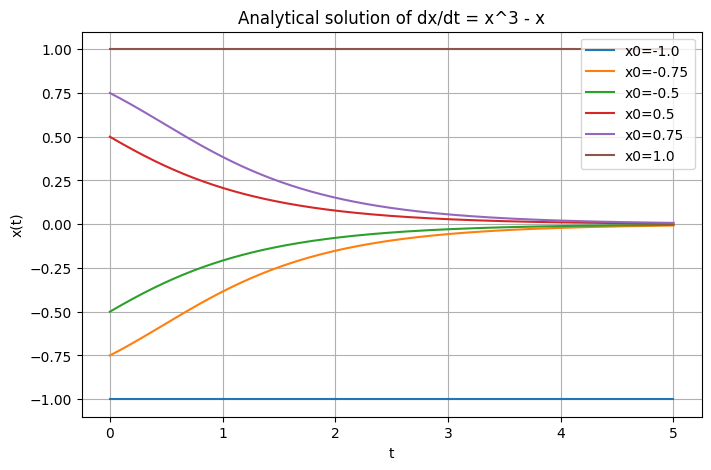

In [ ]:
# @title Plot Analytical Solution
import numpy as np
import matplotlib.pyplot as plt

def x_analytic(t, x0):
    # Handle equilibrium points
    if x0 == 0:
        return np.zeros_like(t)
    if abs(x0) == 1:
        return x0 * np.ones_like(t)

    K2 = (x0**2 - 1) / x0**2
    return np.sign(x0) / np.sqrt(1 - K2 * np.exp(2*t))

# Time range
t = np.linspace(0, 5, 400)

# Initial conditions
ics = [-1.0, -0.75, -0.5, 0.5, 0.75, 1.0]

plt.figure(figsize=(8,5))
for x0 in ics:
    plt.plot(t, x_analytic(t, x0), label=f"x0={x0}")

plt.title("Analytical solution of dx/dt = x^3 - x")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.grid(True)
plt.legend()
plt.show()


As we can see, the solution varies significantly with the initial position $x(t_0)$.

Let's define our intended goal as:
* to learn the solution of x(t) from $t_0=0$ to $t_f = 1$ seconds
* for initial positions from $x(t_0)=-.9$ to $0.9$.

To show how this works, I will first present aspect of the code with explanation in blocks of text, followed by a single cell that includes all the code needed to run the model.

### 🔹 Generate Training Data

To do this we need to generate training data across this range.

Let's choose $x_0$ values, e.g. $ x_0 \in \{-0.9, -0.75, -0.5, 0.5, 0.75, 0.9\}, $

then integrate the ODE numerically (e.g. RK4) over $t \in [0, 5]$, with time step $ \Delta t $.

*Note*: in this case we could also use the analytical solution for the trajectory.

The training date then needs to be paired $(t_i, x(t_i))$ for all trajectories.

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# -----------------------------
# True ODE: dx/dt = x^3 - x
# -----------------------------
def f_true(t, x):
    return x**3 - x

# Generate training data
def generate_data(x0, T=3.0, steps=300):
    t = torch.linspace(0, T, steps, device=device)
    x = torch.zeros(steps, device=device)
    x[0] = x0
    dt = t[1] - t[0]
    for i in range(steps - 1):
        k1 = f_true(t[i], x[i])
        k2 = f_true(t[i] + dt/2, x[i] + dt*k1/2)
        k3 = f_true(t[i] + dt/2, x[i] + dt*k2/2)
        k4 = f_true(t[i] + dt,   x[i] + dt*k3)
        x[i+1] = x[i] + dt*(k1 + 2*k2 + 2*k3 + k4)/6
    return t, x

# Training dataset
ics = [-0.9, -0.75, -0.5, 0.5, 0.75, 0.9]
data = [generate_data(torch.tensor(x0, device=device), T=1.0, steps=100) for x0 in ics]

# put training date in pandas data frame
rows = []

for x0, (t, x) in zip(ics, data):
    for ti, xi in zip(t, x):
        rows.append({
            "x0": x0,
            "t": float(ti),
            "x": float(xi)
        })

df = pd.DataFrame(rows)
display(df)

,x0,t,x
0,-0.9,0.000000,-0.900000
1,-0.9,0.010101,-0.898260
2,-0.9,0.020202,-0.896495
3,-0.9,0.030303,-0.894705
4,-0.9,0.040404,-0.892889
...,...,...,...
595,0.9,0.959596,0.620330
596,0.9,0.969697,0.616472
597,0.9,0.979798,0.612609
598,0.9,0.989899,0.608741


using the Pandas data frame, you can filter the outputs to look at the result of a specific case.

### 🔹 Setting Up The Neural Network

We now need to setup the Neural Network itself. In the code below we set up a class to store the network and added a series of nodes using the [Pytorch](https://pytorch.org) library, currently one of the most popular libraries for machine learning.




In [ ]:
import torch.nn as nn

# -----------------------------
# Neural ODE vector field
# -----------------------------
class ODEFunc(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
        for m in self.net:
            if isinstance(m, nn.Linear):
                #nn.init.uniform_(m.weight, -0.001, 0.001)
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, t, x):
        x = x.view(-1, 1)
        x = torch.clamp(x, -2.0, 2.0)
        out = self.net(x)
        #out = torch.clamp(out, -0.5, 0.5)
        return out.view(-1)
func = ODEFunc()

The network, defined by the func object, is a simple feed-forward neural network implemented using PyTorch's nn.Sequential module. It consists of the following layers:

1. **The Input Layer** - nn.Linear(1, 32): This is the input layer. It takes a single input feature (representing x in the ODE, as t is passed separately to the forward method but not directly to the net) and transforms it into a 32-dimensional output. This means there's 1 input neuron connected to 32 neurons in the first hidden layer.
2. **Layer 1** - nn.Tanh(): This is an activation function (hyperbolic tangent) applied element-wise to the output of the first linear layer. It introduces non-linearity into the model, allowing it to learn more complex relationships.
3. **Layer 2** - nn.Linear(32, 32): This is a hidden layer. It takes the 32 outputs from the previous Tanh layer and transforms them into another 32-dimensional output. This represents 32 input neurons connecting to 32 output neurons.
4. **Layer 3** - nn.Tanh(): Another hyperbolic tangent activation function, applied to the output of the second linear layer.
5. **Output Layer** - nn.Linear(32, 1): This is the output layer. It takes the 32 outputs from the previous Tanh layer and reduces them to a single output feature. This single output represents the predicted dx/dt value (the derivative).

We can use libraries like *torchview* to provide a graphical representation of the network.

In [ ]:
!pip install torchview -q
import torch.nn as nn
from torchview import draw_graph

# Draw the graph using a dummy input shape. The ODEFunc takes 't' and 'x' as input. Each is a single scalar.
model_graph = draw_graph(func, input_size=((1,), (1,)), expand_nested=True)

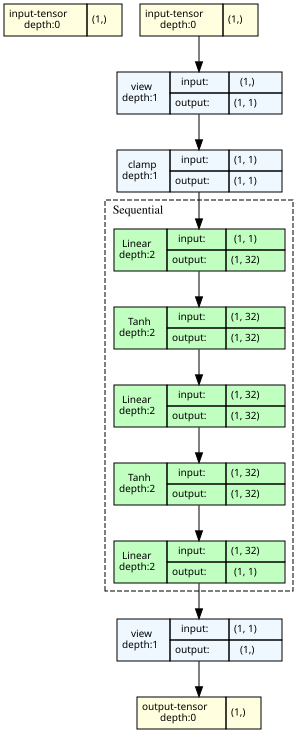

In [ ]:
model_graph.visual_graph

Alternatively, you can use the *networkx* to draw links between every node, but as you can see this will quickly overwhelm the figure.

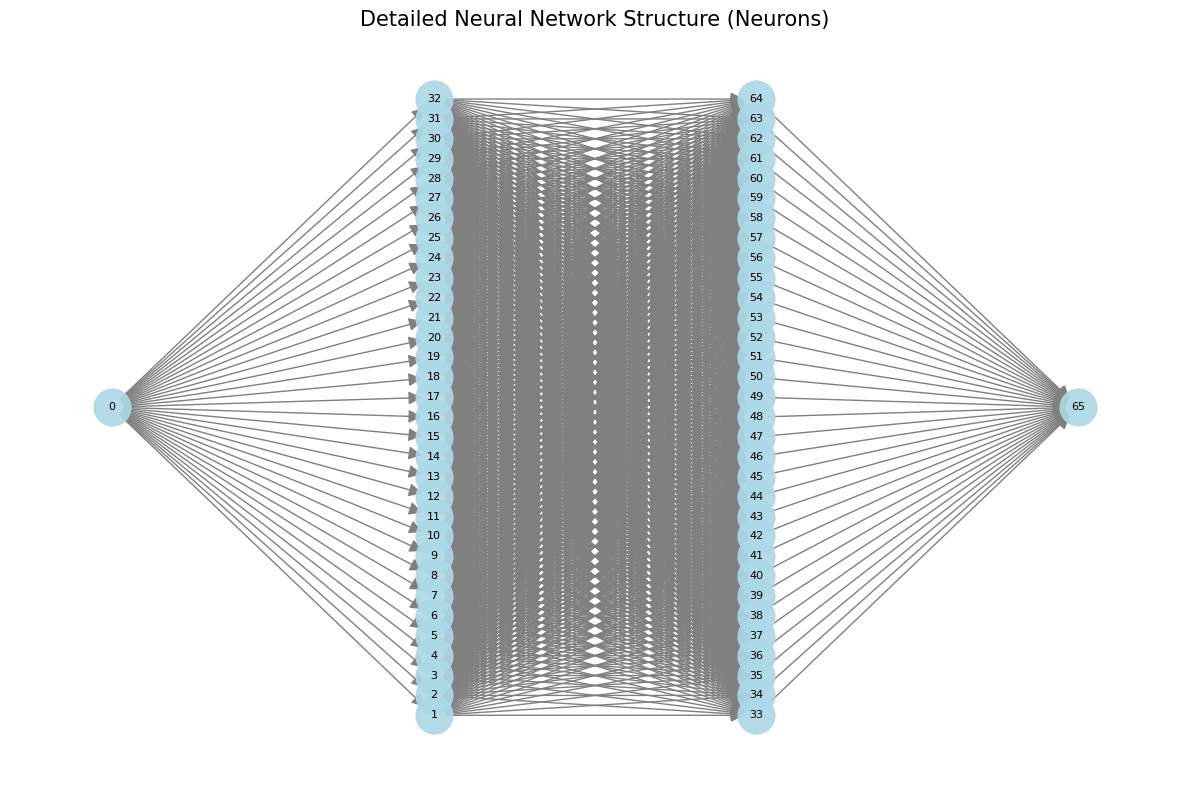

In [ ]:
!pip install graphviz -q
import networkx as nx
import matplotlib.pyplot as plt

def visualize_all_neurons(model):
    G = nx.DiGraph()
    node_counter = 0
    layer_nodes = [] # Stores lists of nodes for each layer

    # Input layer
    input_neurons = [node_counter]
    G.add_node(node_counter, layer='input', label='Input')
    node_counter += 1
    layer_nodes.append(input_neurons)

    current_input_size = 1 # Initial input to the first linear layer is 1

    for i, layer in enumerate(model.net):
        if isinstance(layer, nn.Linear):
            # Output neurons for this linear layer
            output_neurons = list(range(node_counter, node_counter + layer.out_features))
            for n in output_neurons:
                G.add_node(n, layer=f'hidden_{i}', label=f'H{i}_{n}')
            node_counter += layer.out_features

            # Add edges from previous layer's nodes to current layer's output nodes
            for prev_node in layer_nodes[-1]:
                for current_node in output_neurons:
                    G.add_edge(prev_node, current_node)
            layer_nodes.append(output_neurons)
            current_input_size = layer.out_features
        elif isinstance(layer, nn.Tanh):
            # Tanh is an element-wise activation, doesn't change neuron count or connections at this level
            pass

    # Plotting
    plt.figure(figsize=(12, 8))
    pos = {}
    x_offset = 0
    y_step = 1.0
    max_neurons_in_layer = max(len(ln) for ln in layer_nodes)

    for layer_idx, nodes_in_layer in enumerate(layer_nodes):
        # Center the neurons vertically
        y_start = (max_neurons_in_layer - len(nodes_in_layer)) * y_step / 2.0
        for i, node_id in enumerate(nodes_in_layer):
            pos[node_id] = (x_offset, y_start + i * y_step)
        x_offset += 2 # Increase x_offset for the next layer

    nx.draw_networkx_nodes(G, pos, node_size=700, node_color='lightblue', alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=20)
    nx.draw_networkx_labels(G, pos, font_size=8, font_color='black')

    plt.title('Detailed Neural Network Structure (Neurons)', size=15)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

visualize_all_neurons(func)

### 🔹 Training the Model

While Pytorch is installed by default in Google Colab, we will need to install `torchdiffeq` for the ODE functionality.

In [ ]:
# Needed install torchdiffeq from the Pytorch
!pip install torchdiffeq -q

The `data` variable of the training set is a list of 5 elements, one for each initial condition. We can check the size of this as follows.

In [ ]:
print("data length: ",len(data))
print("element length: ",len(data[0]))
# Initialize j before the loop
for j, i in enumerate(data[0]):
  print("index ",j," length: ",len(data[0][0]))

data length:  5
element length:  2
index  0  length:  100
index  1  length:  100


We need to define a loss function and include it in our training loop. In this case we will take the mean squared error between all points in the predicted and training data set, and accumulate this loss across all different training sets. This loss function is set in the code for the training loop below as `loss += torch.mean((pred - x)**2)`.

This code has been set to run on either the Colab CPU or GPU runtimes.

To run on a GPU
1. In the top menu, click on Runtime > Change runtime type.
2. Under Hardware accelerator, select T4 GPU (or any available GPU tier).
3. Need to define operation `device` and pass torch data to that device

OOn the free instance, the GPU is not particularly fast, so you may find this problem runs faster on the CPU.

For completeness I have included the full code for this problem in the cell below.

*Note*: each time you redefine or create the neural network you will overwrite the previous training.

Using device: cpu
Epoch 0, Loss = 0.112905
Epoch 200, Loss = 0.017580
Epoch 400, Loss = 0.013510
Epoch 600, Loss = 0.000955
Epoch 800, Loss = 0.000770
Epoch 1000, Loss = 0.000631
Epoch 1200, Loss = 0.000526
Epoch 1400, Loss = 0.000453
Epoch 1600, Loss = 0.000399
Epoch 1800, Loss = 0.000351


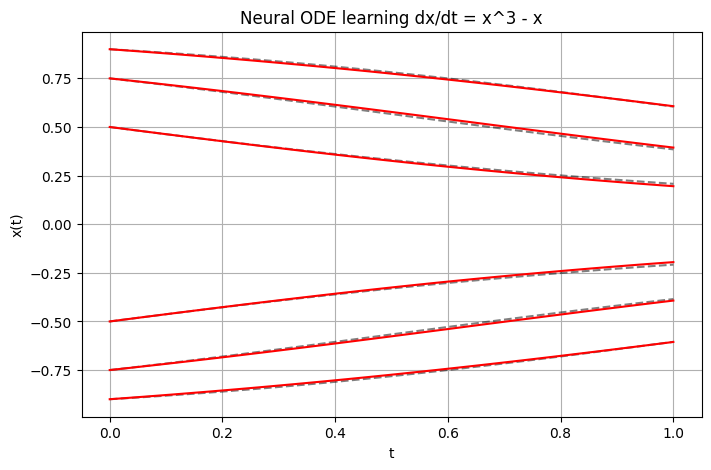

In [ ]:
!pip install torchdiffeq -q
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from torchdiffeq import odeint

# -----------------------------
# Select device
# -----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

torch.set_default_dtype(torch.float32)

# -----------------------------
# True ODE: dx/dt = x^3 - x
# -----------------------------
def f_true(t, x):
    return x**3 - x

# Generate training data
def generate_data(x0, T=3.0, steps=300):
    t = torch.linspace(0, T, steps, device=device)
    x = torch.zeros(steps, device=device)
    x[0] = x0
    dt = t[1] - t[0]
    for i in range(steps - 1):
        k1 = f_true(t[i], x[i])
        k2 = f_true(t[i] + dt/2, x[i] + dt*k1/2)
        k3 = f_true(t[i] + dt/2, x[i] + dt*k2/2)
        k4 = f_true(t[i] + dt,   x[i] + dt*k3)
        x[i+1] = x[i] + dt*(k1 + 2*k2 + 2*k3 + k4)/6
    return t, x

# Training dataset
ics = [-0.9, -0.75, -0.5, 0.5, 0.75, 0.9]
data = [generate_data(torch.tensor(x0, device=device), T=1.0, steps=100) for x0 in ics]

# -----------------------------
# Neural ODE vector field
# -----------------------------
class ODEFunc(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
        for m in self.net:
            if isinstance(m, nn.Linear):
                #nn.init.uniform_(m.weight, -0.001, 0.001)
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, t, x):
        x = x.view(-1, 1)
        x = torch.clamp(x, -2.0, 2.0)
        out = self.net(x)
        #out = torch.clamp(out, -0.5, 0.5)
        return out.view(-1)

# this is a call to the ODE network that return the output
func = ODEFunc().to(device)

# -----------------------------
# Manual RK4 integrator
# -----------------------------
def integrate_nn(func, x0, t):
    xs = [x0]
    dt = t[1] - t[0]

    for i in range(len(t) - 1):
        x_i = xs[-1]

        k1 = func(t[i], x_i)
        k2 = func(t[i], x_i + dt*k1/2)
        k3 = func(t[i], x_i + dt*k2/2)
        k4 = func(t[i], x_i + dt*k3)

        x_next = x_i + dt*(k1 + 2*k2 + 2*k3 + k4)/6
        xs.append(x_next)

    return torch.stack(xs).squeeze()


# -----------------------------
# Training loop
# -----------------------------
optimizer = torch.optim.Adam(func.parameters(), lr=1e-3)

for epoch in range(2000):
    loss = 0.0
    for t, x in data:
        x0 = x[0].unsqueeze(0)     # shape [1]

        #pred = integrate_nn(func, x0, t)
        # using func to obtain ODE estimate from the NN
        pred = odeint(func,x0,t,method='dopri5',rtol=1e-5,atol=1e-6).squeeze()

        if not torch.isfinite(pred).all():
            print("Non-finite in pred")
            print(pred[:10])
            raise RuntimeError("ODE produced non-finite values")

        loss += torch.mean((pred - x)**2)

    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(func.parameters(), max_norm=1.0)
    optimizer.step()

    if epoch % 200 == 0:
        print(f"Epoch {epoch}, Loss = {loss.item():.6f}")

# -----------------------------
# Plotting (detach for numpy)
# -----------------------------
plt.figure(figsize=(8,5))
for t, x in data:
    x0 = x[0].unsqueeze(0)
    pred = integrate_nn(func, x0, t).detach().cpu()

    plt.plot(t.cpu().numpy(), x.cpu().numpy(), 'k--', alpha=0.5)
    plt.plot(t.cpu().numpy(), pred.numpy(), 'r')

plt.title("Neural ODE learning dx/dt = x^3 - x")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.grid(True)
plt.show()


This training will take 15-20 minutes if you choose to re-run it. Once the model is trained, we can save the trained parameters and download them from our notebook to be re-used at a later time without needing to repeat the training.

As you can see, this network has done a good job of learning the training data. If the loss converges and the model does not match the training data, you need to change the structure of the network to ensure it has a more appropriate type and/or level of nodes - *the example here is pretty good*.

In [ ]:
# A save model weights
PATH = "model_weights.pth"
torch.save(func.state_dict(), PATH)

*Note:* This only saves the weights, not the structure of the network. To reload these you will need to generate the structure (re-run the cells that define the network) before loading the weights.



In [ ]:
# load weights from tile
weights = torch.load('model_weights.pth', weights_only=True)

# Inject the weights into the initialized model structure
func.load_state_dict(weights)

# CRITICAL: Set to evaluation mode if you are performing inference
func.eval()

ODEFunc(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): Tanh()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)

## 📂 10.2.5 Advantages of a Neural ODE

---

Compared to a plain Neural Network that might be used to train the trajectory $x(t)$ directly, the Neural ODE has several advantages for a dynamical system with an underlying differential equation.

1. Extrapolation in time
A plain NN can only predict at the time points it was trained on.
A Neural ODE can integrate forward to any time horizon.
2. Consistency with dynamics
A plain NN learns a mapping [ x(t) \to x(t+\Delta) ].
A Neural ODE learns the vector field [ f(x) ], which is physically meaningful.
3. Stability and smoothness
A plain NN produces jagged predictions.
A Neural ODE produces smooth trajectories because it is integrated by a solver.

Let's test some of this behaviour for our previously trained model. Of course, for a fair evaluation we need to use separate data from that seen by model during training. We can do this by using different initial conditions.

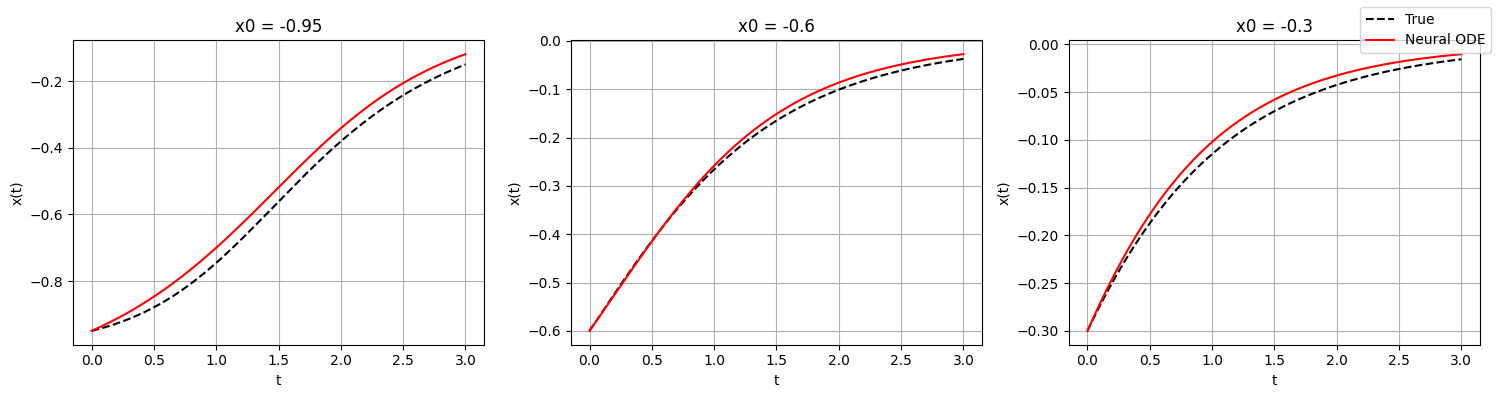

In [ ]:
# test initial conditions x0
test_ics = [-0.95, -0.6, -0.3]

# generate test data - use the RK4 method contain in generate_date() from before
test_data = [generate_data(torch.tensor(x0, device=device), T=3.0, steps=200)
             for x0 in test_ics]

# generate predictions using the trained neural ODE.
# Create a row of 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (x0, (t, x_true)) in zip(axes, zip(test_ics, test_data)):
    # Predict with Neural ODE
    x0_tensor = x_true[0].unsqueeze(0)
    x_pred = odeint(func, x0_tensor, t).squeeze().detach().cpu()

    # Plot true trajectory
    ax.plot(t.cpu(), x_true.cpu(), 'k--', label='True')

    # Plot NODE prediction
    ax.plot(t.cpu(), x_pred, 'r', label='Neural ODE')

    ax.set_title(f"x0 = {x0}")
    ax.set_xlabel("t")
    ax.set_ylabel("x(t)")
    ax.grid(True)

# Put legend only once (top‑right of figure)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right')

plt.tight_layout()
plt.show()


Here we can see that the learned ODE provides a smooth solution in all cases, and with the exception of the $x0=-0.95$ case which is close to a rapid change in the solution at $x0=1$, the model is able to do an excellent job of predicting the path within the training range from $t=0$ to $1.0$. Despite never seeing the behaviour beyond $t=1$, this model is able to do a pretty good job extrapolating the time series, a task that would be difficult for a plain NN.

What the Neural ODE has attempted to learn is the ODE, $f(x) = x^3-x$. We can see how this has performed below by plotting the trained $f(x)$, showcasing the potential to learn the ODE rather than just a trajectory with nothing to tell us why the system would follow that path.

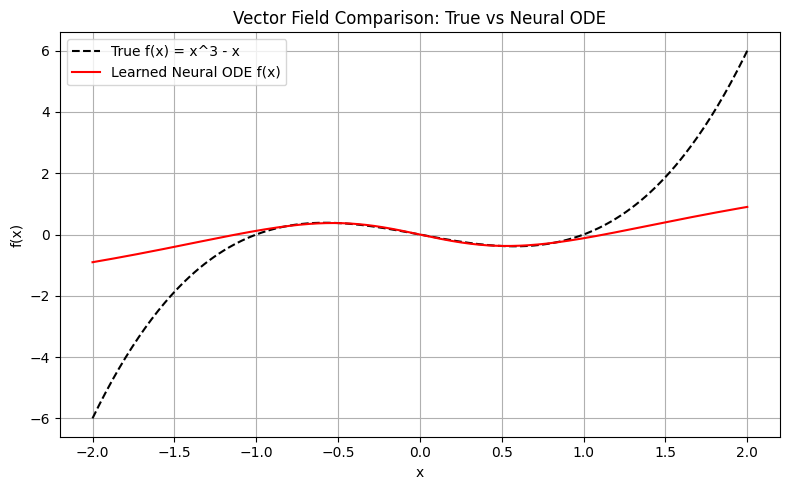

In [ ]:
import matplotlib.pyplot as plt

# Full domain to evaluate the vector field
xs = torch.linspace(-2.0, 2.0, 400, device=device)

# True vector field
f_true_vals = xs**3 - xs

# Learned vector field
f_pred_vals = func(None, xs).detach().cpu()

plt.figure(figsize=(8,5))

# Plot true derivative
plt.plot(xs.cpu(), f_true_vals.cpu(), 'k--', label='True f(x) = x^3 - x')

# Plot learned derivative
plt.plot(xs.cpu(), f_pred_vals, 'r', label='Learned Neural ODE f(x)')

plt.title("Vector Field Comparison: True vs Neural ODE")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

We see here that the Neural ODE has done a good job of learning the underlying dynamics - the ODE - of the system, noting that the system only received training data between $x = -0.9$ to $0.9$. Outside this range, the performance falls off as neural networks struggle with extrapolation, particularly when the dynamics change outside the training domain.

## 📂 10.2.6 Comparing the Neural ODE to a Plain Neural Network

---

*How does this compare to a plain Neural Network?*

Consider, if instead of trying to learn the ODE, we tried to learn to predict the next step along a trajectory, for example:
$$(t_i, x(t_i)) → x(t_{i+1}).$$

To do this we need to provide training data that consists of pairs of the current time and position, and the corresponding position in the next time step.

This already creates the first limitation - *the time step would be fixed!*

Using device: cpu
Plain NN Epoch 0, Loss = 0.338842
Plain NN Epoch 200, Loss = 0.000202
Plain NN Epoch 400, Loss = 0.000173
Plain NN Epoch 600, Loss = 0.000144
Plain NN Epoch 800, Loss = 0.000117
Plain NN Epoch 1000, Loss = 0.000093
Plain NN Epoch 1200, Loss = 0.000072
Plain NN Epoch 1400, Loss = 0.000054
Plain NN Epoch 1600, Loss = 0.000039
Plain NN Epoch 1800, Loss = 0.000026


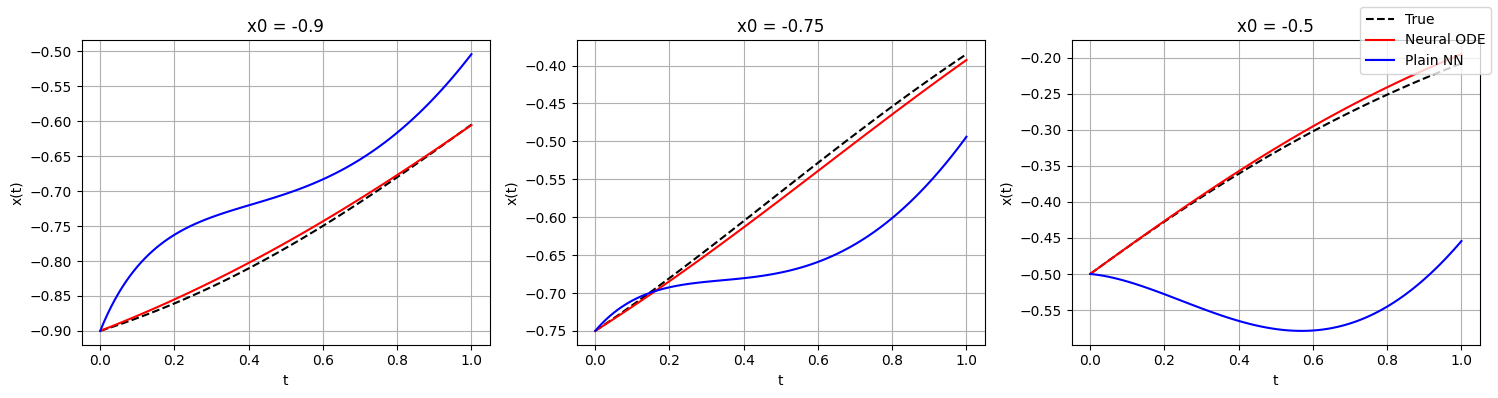

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ---------------------------------------------------------
# True ODE: dx/dt = x^3 - x
# ---------------------------------------------------------
def f_true(t, x):
    return x**3 - x

def generate_data(x0, T=1.0, steps=100):
    t = torch.linspace(0, T, steps, device=device)
    x = torch.zeros(steps, device=device)
    x[0] = x0
    dt = t[1] - t[0]
    for i in range(steps - 1):
        k1 = f_true(t[i], x[i])
        k2 = f_true(t[i] + dt/2, x[i] + dt*k1/2)
        k3 = f_true(t[i] + dt/2, x[i] + dt*k2/2)
        k4 = f_true(t[i] + dt,   x[i] + dt*k3)
        x[i+1] = x[i] + dt*(k1 + 2*k2 + 2*k3 + k4)/6
    return t, x

# Training data (same as NODE)
ics = [-0.9, -0.75, -0.5, 0.5, 0.75, 0.9]
data = [generate_data(torch.tensor(x0, device=device)) for x0 in ics]

# ---------------------------------------------------------
# Plain Neural Network baseline
# Learns discrete mapping: (t_i, x_i) -> x_{i+1}
# ---------------------------------------------------------
class PlainNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, t, x):
        inp = torch.stack([t, x], dim=-1)  # shape [batch, 2]
        return self.net(inp).squeeze(-1)

plain_nn = PlainNN().to(device)

# ---------------------------------------------------------
# Build training dataset for plain NN
# ---------------------------------------------------------
pairs_t = []
pairs_x = []
targets = []

for t, x in data:
    pairs_t.append(t[:-1])
    pairs_x.append(x[:-1])
    targets.append(x[1:])

pairs_t = torch.cat(pairs_t).to(device)
pairs_x = torch.cat(pairs_x).to(device)
targets = torch.cat(targets).to(device)

# ---------------------------------------------------------
# Train the plain NN
# ---------------------------------------------------------
opt = torch.optim.Adam(plain_nn.parameters(), lr=1e-3)

for epoch in range(2000):
    pred = plain_nn(pairs_t, pairs_x)
    loss = torch.mean((pred - targets)**2)

    opt.zero_grad()
    loss.backward()
    opt.step()

    if epoch % 200 == 0:
        print(f"Plain NN Epoch {epoch}, Loss = {loss.item():.6f}")

# ---------------------------------------------------------
# Rollout function for plain NN (autoregressive)
# ---------------------------------------------------------
def rollout_plain_nn(model, x0, t):
    xs = [x0]
    for i in range(len(t)-1):
        x_i = xs[-1]
        x_next = model(t[i], x_i)
        xs.append(x_next)
    return torch.stack(xs)

# ---------------------------------------------------------
# Compare True vs Neural ODE vs Plain NN (3 cases side-by-side)
# ---------------------------------------------------------
from torchdiffeq import odeint

# Neural ODE model (must already be trained)
# Using your existing ODEFunc "func"
# ---------------------------------------------------------

#test_ics = [-0.95, -0.6, -0.3]
test_ics = [-0.9, -0.75, -0.5] # this is not a true test as the NN has seen these conditions
test_data = [generate_data(torch.tensor(x0, device=device)) for x0 in test_ics]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (x0, (t, x_true)) in zip(axes, zip(test_ics, test_data)):
    x0_tensor = x_true[0]

    # Neural ODE prediction
    x_pred_node = odeint(func, x0_tensor.unsqueeze(0), t).squeeze().detach().cpu()

    # Plain NN prediction
    x_pred_plain = rollout_plain_nn(plain_nn, x0_tensor, t).detach().cpu()

    # Plot true trajectory
    ax.plot(t.cpu(), x_true.cpu(), 'k--', label='True')

    # Plot NODE
    ax.plot(t.cpu(), x_pred_node, 'r', label='Neural ODE')

    # Plot plain NN
    ax.plot(t.cpu(), x_pred_plain, 'b', label='Plain NN')

    ax.set_title(f"x0 = {x0}")
    ax.set_xlabel("t")
    ax.set_ylabel("x(t)")
    ax.grid(True)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right')

plt.tight_layout()
plt.show()


The loss on the training for the plain NN is low, but when we use the predictions $(t_i, x(t_i)) → x(t_{i+1})$ to build the solution, they do a poor jobs of reconstructing the actual trajectory. The plain NN learns the next step, but not the full trajectory.

The reason for this is that training loss in our Plain-NN measures one-step error, but the trajectories we see here depends on multi-step error accumulation, hence a much lower loss is needed to enable a good solution.

1. The plain NN learns a discrete map
$$x_{i+1} = g(t_i, x_i)$$
2. The Neural ODE learns a continuous vector field
$$\frac{dx}{dt} = f(x)$$

So, did the plain NN do a good job of learning the discrete map?

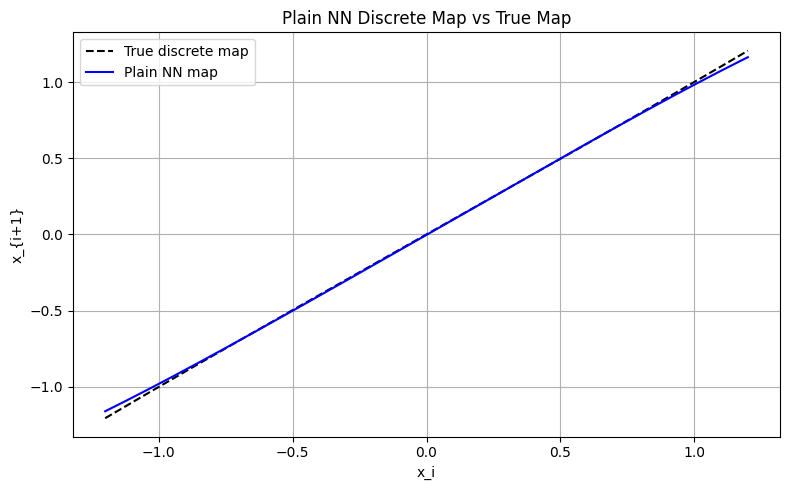

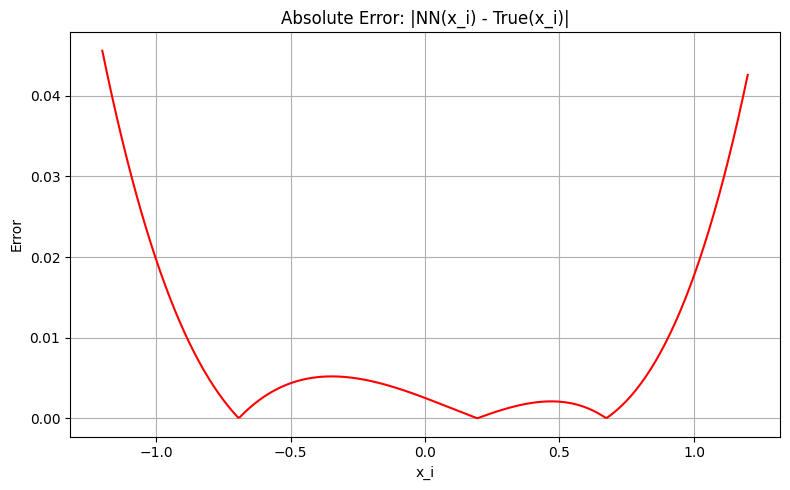

In [ ]:
import torch
import matplotlib.pyplot as plt

# Use same dt as training data
T = 1.0
steps = 100
dt = T / (steps - 1)

# Build a dense grid of x values
xs = torch.linspace(-1.2, 1.2, 400, device=device)

# True discrete map: x_{i+1} = x_i + dt * f(x_i)
f_true_vals = xs**3 - xs
true_map = xs + dt * f_true_vals

# Plain NN discrete map: x_{i+1} = NN(t_i, x_i)
# Use t=0 for all points (the NN was trained on uniform t anyway)
t0 = torch.zeros_like(xs)
nn_map = plain_nn(t0, xs).detach().cpu()

# Move true map to CPU
true_map_cpu = true_map.detach().cpu()

# Plot
plt.figure(figsize=(8,5))

plt.plot(xs.cpu(), true_map_cpu, 'k--', label='True discrete map')
plt.plot(xs.cpu(), nn_map, 'b', label='Plain NN map')

plt.title("Plain NN Discrete Map vs True Map")
plt.xlabel("x_i")
plt.ylabel("x_{i+1}")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Optional: plot error
plt.figure(figsize=(8,5))
plt.plot(xs.cpu(), (nn_map - true_map_cpu).abs(), 'r')
plt.title("Absolute Error: |NN(x_i) - True(x_i)|")
plt.xlabel("x_i")
plt.ylabel("Error")
plt.grid(True)
plt.tight_layout()
plt.show()


When comparing the predicted step $x_{n+1}$ from $x_{n}$ the top plot shows what initially appears to be a good prediction. Looking at the absolute error we can see that the error here is greater towards the edges and beyond the training domain, but for the majority of the domain is of the order of 0.05. However, we can see from the trajectories that a much lower error would be needed to use this plain NN prediction effectively.

## 📂 10.2.7 Determining the Loss Gradients for a Neural ODE (Under the Hood - Non Examined)

---

Consider this section an extension to what we have discussed so far, to explain how the loss derivatives can be determined when the loss comes from the integral of the output of the Neural ODE, rather than the direct output of the network.

To keep the mathematics a little easier to follow, as per Worsham and Kalita (2025), let's assume that the we have a Neural ODE that consists of a simple explicit Euler method, and assume we require only three steps from $t=t_0$ to $T$.

\begin{align}
x_{1} = x_0 + f_\theta(x_0)\Delta t,\\
x_{2} = x_1 + f_\theta(x_1)\Delta t,\\
x_{3} = x_2 + f_\theta(x_2)\Delta t.\\
\end{align}

where $f_\theta(x_i)$ is the output of the Neural ODE that takes the place of the ODE in the Euler Method, and $\Delta t$ is the step size.

Consistent with sections 10.2.3-10.2.6, the loss function is based on the output of the integration, but at all time steps. For the present example, let's focus on the loss after the three steps above, i.e.

$$\mathcal{L}(x_3,t_3) = \frac{1}{2}(x_3-y(t_3))^2.$$

To determine the influence of each network parameter on the loss $\partial \mathcal{L}/\partial \theta_i$, we need to recognise that the same parameters, 𝜃, are used in each time step. This creates a backpropagation-through-time (BPTT) paradigm, that is, the gradient with respect to 𝜃 must be computed at each stage and then combined.

We will leave the derivation of this to Worsham and Kalita (2025), but the result is that the loss gradients can be expressed as the sum of the sensitivities of each step of the Euler Method,

$$\frac{d\mathcal{L}}{d\theta} = \sum^0_{i=f} a_i\frac{\partial f_\theta(x_i)}{\partial \theta}\Delta t.$$

This requires a backwards pass to compute the sensitivities, but a forward pass is needed to compute the states over time. Standard deep learning libraries will store the states from the forward pass and look them up during the backwards pass. The training of a Neural ODE is more complex and more time consuming.

As will most numerical methods, there are a range of different techniques that can be used to speed up the process, but we have already gone into more than enough detail here.

If you wish to dig into the weeds of this method, I recommend you work through Worsham and Kalita (2025).


## 🔗 Bridge to Notebook 10.3

This notebook introduced **Neural Ordinary Differential Equations (Neural ODEs)** as a powerful machine learning framework for modeling continuous-time dynamical systems. You should now understand how a neural network can be embedded within an ODE solver to learn the underlying vector field of a system, rather than just discrete mappings.

We explored how to:

*   Define a neural network (`ODEFunc`) to represent the derivative function $f(x)$ in $\frac{dx}{dt} = f(x)$.
*   Generate synthetic training data from a known ODE to train the Neural ODE.
*   Train the Neural ODE by minimizing the difference between the integrated neural network output and the true trajectories.
*   Visualize the learned vector field and predicted trajectories, comparing them to the true system behavior.
*   Appreciate the advantages of Neural ODEs over traditional neural networks for dynamic systems, particularly in terms of learning physical laws and extrapolation capabilities.

In Notebook 10.3, we will delve into **Physics-Informed Neural Networks (PINNs)**, which take the integration of physics and machine learning a step further by directly incorporating the governing physical equations (like ODEs or PDEs) into the neural network's loss function. This allows us to train models that are not only data-driven but also inherently consistent with known physical laws.

#🤖 AI Acknowledgment

MS CoPilot v25.6.440430001 was used to proof read this notebook and provided the Pytorch input code for Neural ODE solver that was used as an example. The code underwent multiple revisions of the methods and neural network inorder to achieve a convergent training.